# Desafio 1 — Análise de Crédito

**Objetivo:** investigar os fatores associados à inadimplência e avaliar se o histórico de propostas permite identificar solicitações de maior risco.

A variável `inadimplente` é binária, portanto o problema é de classificação supervisionada. O modelo principal exigido pelo desafio é a Regressão Logística.

## 1. Configuração e importações

A execução é reprodutível com `RANDOM_STATE = 42`. O notebook usa o arquivo bruto e a mesma rotina de tratamento versionada em `tratamento_dados.py`.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "dataset.csv").exists():
    PROJECT_DIR = PROJECT_DIR / "desafios" / "analise-credito"
sys.path.insert(0, str(PROJECT_DIR))
from tratamento_dados import tratar_dados

print(f"Diretório do projeto: {PROJECT_DIR.resolve()}")

Diretório do projeto: D:\lab\Analise_Credito\desafios\analise-credito


## 2. Carregamento e entendimento do problema

Cada linha representa uma proposta de crédito. A resposta `inadimplente` indica se houve inadimplência após o acompanhamento da proposta. As demais colunas são potenciais variáveis explicativas disponíveis no momento da análise.

In [2]:
bruto = pd.read_csv(PROJECT_DIR / "dataset.csv")
colunas_esperadas = [
    "idade", "estado", "escolaridade", "renda_mensal",
    "tempo_emprego_anos", "score_credito", "valor_solicitado",
    "prazo_meses", "finalidade", "dividas_ativas", "inadimplente",
]
assert list(bruto.columns) == colunas_esperadas
assert set(bruto["inadimplente"].unique()) == {0, 1}
print(f"Dimensões: {bruto.shape[0]:,} linhas x {bruto.shape[1]} colunas")
display(bruto.head())
display(bruto.dtypes.rename("tipo").to_frame())

Dimensões: 5,000 linhas x 11 colunas


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,"2,911.820",14,690,"5,934.190",60,Viagem,1,0
1,49,RR,Ensino Médio,"3,176.430",5,676,"6,791.380",24,Outros,2,0
2,48,AL,Ensino Superior,"3,429.400",23,558,"14,666.780",24,Outros,5,1
3,59,GO,Ensino Fundamental,"10,096.700",2,739,"19,053.240",24,Reforma,0,0
4,37,RJ,Ensino Fundamental,"3,033.250",24,797,"6,171.310",6,Educação,0,1


,tipo
idade,int64
estado,str
escolaridade,str
renda_mensal,float64
tempo_emprego_anos,int64
score_credito,int64
valor_solicitado,float64
prazo_meses,int64
finalidade,str
dividas_ativas,int64


### Qualidade dos dados brutos

In [3]:
qualidade_bruta = pd.DataFrame({
    "ausentes": bruto.isna().sum(),
    "valores_distintos": bruto.nunique(),
    "tipo": bruto.dtypes.astype(str),
})
print(f"Duplicatas exatas: {bruto.duplicated().sum()}")
display(qualidade_bruta)
display(bruto["inadimplente"].value_counts(normalize=False).rename("quantidade").to_frame())
print(f"Taxa bruta de inadimplência: {bruto['inadimplente'].mean():.1%}")

Duplicatas exatas: 19


,ausentes,valores_distintos,tipo
idade,0,73,int64
estado,0,85,str
escolaridade,0,4,str
renda_mensal,0,4921,float64
tempo_emprego_anos,0,32,int64
score_credito,0,428,int64
valor_solicitado,0,4937,float64
prazo_meses,0,7,int64
finalidade,0,6,str
dividas_ativas,0,8,int64


,quantidade
inadimplente,
0,3280
1,1720


Taxa bruta de inadimplência: 34.4%


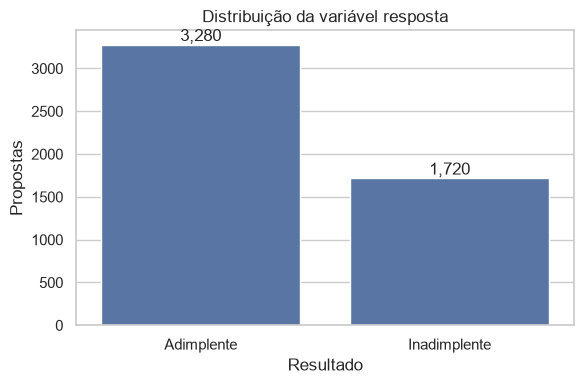

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
contagem_alvo = bruto["inadimplente"].map({0: "Adimplente", 1: "Inadimplente"}).value_counts()
sns.barplot(x=contagem_alvo.index, y=contagem_alvo.values, ax=ax)
ax.set(title="Distribuição da variável resposta", xlabel="Resultado", ylabel="Propostas")
for i, value in enumerate(contagem_alvo.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 3. Limpeza, tratamento e engenharia de atributos

Decisões aplicadas:

- espaços extras em categorias são removidos;
- idades acima de 100 são corrigidas apenas quando são exatamente dez vezes uma idade plausível;
- tempos de emprego acima do domínio observado de 30 anos são marcados como ausentes, sem adivinhação;
- duplicatas exatas são removidas;
- a razão `valor_solicitado / renda_mensal` representa o comprometimento relativo da renda.

A imputação do tempo de emprego não é feita globalmente: durante a modelagem, a mediana será aprendida apenas no treino dentro do pipeline. Isso evita vazamento de informação.

In [5]:
df = tratar_dados(bruto)
df.to_csv(PROJECT_DIR / "dataset_tratado.csv", index=False)

resumo_tratamento = pd.DataFrame({
    "antes": [len(bruto), bruto["estado"].nunique(), bruto.duplicated().sum(), (bruto["idade"] > 100).sum()],
    "depois": [len(df), df["estado"].nunique(), df.duplicated().sum(), df["idade"].between(18, 75).all()],
}, index=["linhas", "estados_distintos", "duplicatas", "idade_corrigida"])
print(f"Dimensões após tratamento: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Ausências criadas por valores inválidos: {df.isna().sum().sum()}")
display(resumo_tratamento)
display(df.isna().sum().rename("ausentes").to_frame())

  [LOG] 15 idades corrigidas (divididas por 10)
  [LOG] 7 tempos de emprego fora de [0, 30] marcados como ausentes
  [LOG] Duplicatas exatas encontradas nos índices: [884, 1096, 1173, 1728, 2451, 2857, 3089, 3723, 3809, 3918, 4016, 4103, 4283, 4299, 4726, 4763, 4767, 4815, 4868]
  [LOG] Removendo 19 duplicatas exatas (mantendo primeira ocorrência)
Dimensões após tratamento: 4,981 linhas x 12 colunas
Ausências criadas por valores inválidos: 7


,antes,depois
linhas,5000,4981
estados_distintos,85,27
duplicatas,19,0
idade_corrigida,15,True


,ausentes
idade,0
estado,0
escolaridade,0
renda_mensal,0
tempo_emprego_anos,7
score_credito,0
valor_solicitado,0
prazo_meses,0
finalidade,0
dividas_ativas,0


In [6]:
numericas_eda = [
    "idade", "renda_mensal", "tempo_emprego_anos", "score_credito",
    "valor_solicitado", "prazo_meses", "dividas_ativas", "razao_emprestimo_renda",
]
display(df[numericas_eda].describe().T.round(2))
assert df["idade"].between(18, 75).all()
assert df["estado"].nunique() == 27
assert df.duplicated().sum() == 0
assert df["razao_emprestimo_renda"].notna().all()

,count,mean,std,min,25%,50%,75%,max
idade,"4,981.000",46.421,16.791,18.000,32.000,46.000,61.000,75.000
renda_mensal,"4,981.000","5,228.976","3,970.245",100.000,"2,698.380","4,145.870","6,458.740","44,814.190"
tempo_emprego_anos,"4,974.000",12.592,7.291,1.000,6.000,13.000,19.000,30.000
score_credito,"4,981.000",652.461,84.804,335.000,594.000,653.000,710.000,850.000
valor_solicitado,"4,981.000","14,260.293","8,267.027","1,721.480","8,466.240","12,363.960","17,763.210","50,000.000"
prazo_meses,"4,981.000",29.913,15.487,6.000,18.000,24.000,36.000,60.000
dividas_ativas,"4,981.000",1.900,1.864,0.000,0.000,1.000,3.000,7.000
razao_emprestimo_renda,"4,981.000",4.257,5.604,0.130,1.667,2.963,5.273,200.012


## 4. Análise exploratória

As comparações abaixo mostram associação com a resposta. Elas não devem ser interpretadas como causalidade.

In [7]:
variaveis_comparativas = ["score_credito", "renda_mensal", "dividas_ativas", "razao_emprestimo_renda", "valor_solicitado"]
comparativos = []
for coluna in variaveis_comparativas:
    auxiliar = df[[coluna, "inadimplente"]].copy()
    auxiliar["faixa"] = pd.qcut(auxiliar[coluna], 4, duplicates="drop")
    tabela = auxiliar.groupby("faixa", observed=True)["inadimplente"].agg(["count", "mean"]).reset_index()
    tabela.insert(0, "variavel", coluna)
    comparativos.append(tabela)
comparativos_df = pd.concat(comparativos, ignore_index=True)
comparativos_df["mean"] = comparativos_df["mean"].map(lambda value: f"{value:.1%}")
display(comparativos_df)

,variavel,faixa,count,mean
0,score_credito,"(334.999, 594.0]",1258,54.4%
1,score_credito,"(594.0, 653.0]",1253,37.8%
2,score_credito,"(653.0, 710.0]",1231,28.7%
3,score_credito,"(710.0, 850.0]",1239,16.5%
4,renda_mensal,"(99.999, 2698.38]",1246,50.8%
5,renda_mensal,"(2698.38, 4145.87]",1245,36.2%
6,renda_mensal,"(4145.87, 6458.74]",1245,28.7%
7,renda_mensal,"(6458.74, 44814.19]",1245,22.0%
8,dividas_ativas,"(-0.001, 1.0]",2509,27.3%
9,dividas_ativas,"(1.0, 3.0]",1474,37.3%


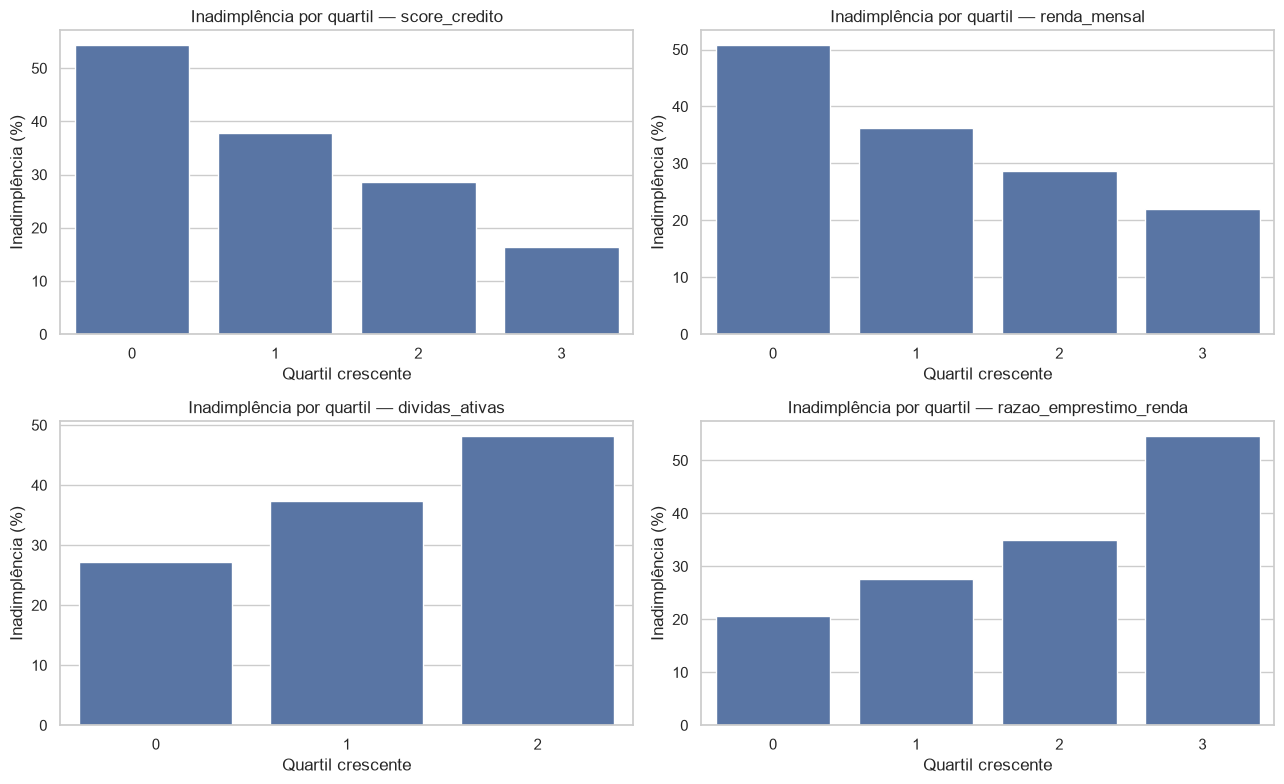

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, coluna in zip(axes.flat, ["score_credito", "renda_mensal", "dividas_ativas", "razao_emprestimo_renda"]):
    auxiliar = df[[coluna, "inadimplente"]].copy()
    auxiliar["faixa"] = pd.qcut(auxiliar[coluna], 4, duplicates="drop")
    taxas = auxiliar.groupby("faixa", observed=True)["inadimplente"].mean().mul(100)
    sns.barplot(x=np.arange(len(taxas)), y=taxas.values, ax=ax)
    ax.set(title=f"Inadimplência por quartil — {coluna}", xlabel="Quartil crescente", ylabel="Inadimplência (%)")
plt.tight_layout()
plt.show()

In [9]:
for coluna in ["escolaridade", "finalidade", "prazo_meses"]:
    tabela = df.groupby(coluna, observed=True)["inadimplente"].agg(quantidade="size", taxa="mean").sort_values("taxa", ascending=False)
    tabela["taxa"] = tabela["taxa"].map(lambda value: f"{value:.1%}")
    print()
    print(coluna)
    display(tabela)


escolaridade


,quantidade,taxa
escolaridade,,
Ensino Medio,2050,36.0%
Pos Graduacao,589,33.6%
Ensino Superior,1932,33.4%
Ensino Fundamental,410,32.2%



finalidade


,quantidade,taxa
finalidade,,
Saude,608,37.5%
Reforma,1112,34.9%
Veiculo,1123,34.5%
Outros,939,33.8%
Educacao,706,33.3%
Viagem,493,32.5%



prazo_meses


,quantidade,taxa
prazo_meses,,
6,292,54.5%
12,688,40.1%
18,649,36.7%
24,1010,34.9%
60,483,31.3%
48,597,30.3%
36,1262,28.4%


### Principais leituras exploratórias

- O quartil inferior de `score_credito` concentra mais inadimplência do que o quartil superior.
- Menor renda e maior quantidade de dívidas ativas estão associados a taxas maiores.
- A razão entre valor solicitado e renda é uma variável derivada útil: ela compara o pedido com a capacidade declarada, em vez de olhar apenas o valor absoluto.
- O prazo de 6 meses apresenta taxa elevada neste conjunto; por ser um padrão observacional, deve ser validado pelo modelo e não usado isoladamente para decisão.

## 5. Preparação para modelagem

Será usado um `Pipeline` para impedir vazamento: imputação, padronização e codificação são ajustadas exclusivamente no treino. A divisão é estratificada para manter a proporção de inadimplentes.

In [10]:
alvo = "inadimplente"
features_originais = [coluna for coluna in colunas_esperadas if coluna != alvo]
features_com_derivada = features_originais + ["razao_emprestimo_renda"]
features_sem_estado = [coluna for coluna in features_com_derivada if coluna != "estado"]
feature_sets = {
    "M1 — originais": features_originais,
    "M2 — originais + razão": features_com_derivada,
    "M3 — sem estado + razão": features_sem_estado,
}

X = df[features_com_derivada]
y = df[alvo]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Treino: {X_train.shape[0]:,} | Teste: {X_test.shape[0]:,}")
print(f"Taxa de inadimplência no treino: {y_train.mean():.1%}")
print(f"Taxa de inadimplência no teste: {y_test.mean():.1%}")
display(pd.DataFrame({nome: pd.Series(colunas) for nome, colunas in feature_sets.items()}))

# --- Análise do racional para remoção de variáveis categóricas (proxy) ---
print("\n=== Análise de proxy geográfico / demográfico ===")
# Verifica associação entre variáveis categóricas e inadimplência
for col in ["estado", "escolaridade", "finalidade"]:
    tabela = df.groupby(col, observed=True)["inadimplente"].agg(
        n="size", taxa="mean"
    ).sort_values("taxa", ascending=False)
    print(f"\n{col} — range de taxa de inadimplência: {tabela['taxa'].min():.1%} a {tabela['taxa'].max():.1%} (amplitude: {(tabela['taxa'].max() - tabela['taxa'].min()):.1%})")
    print(f"  Categorias: {tabela.index.tolist()}")

# Estado tem 27 categorias - maior risco de overfitting e proxy geográfico
# Escolaridade e finalidade têm poucas categorias (4 e 6) e relação mais direta com capacidade de pagamento
print("\n>>> Decisão: Remove-se apenas 'estado' (27 categorias, proxy geográfico, risco de overfitting).")
print("     'escolaridade' e 'finalidade' mantidas — poucas categorias, relação direta com risco.")

Treino: 3,984 | Teste: 997
Taxa de inadimplência no treino: 34.4%
Taxa de inadimplência no teste: 34.4%


,M1 — originais,M2 — originais + razão,M3 — sem estado + razão
0,idade,idade,idade
1,estado,estado,escolaridade
2,escolaridade,escolaridade,renda_mensal
3,renda_mensal,renda_mensal,tempo_emprego_anos
4,tempo_emprego_anos,tempo_emprego_anos,score_credito
5,score_credito,score_credito,valor_solicitado
6,valor_solicitado,valor_solicitado,prazo_meses
7,prazo_meses,prazo_meses,finalidade
8,finalidade,finalidade,dividas_ativas
9,dividas_ativas,dividas_ativas,razao_emprestimo_renda



=== Análise de proxy geográfico / demográfico ===

estado — range de taxa de inadimplência: 29.4% a 42.2% (amplitude: 12.8%)
  Categorias: ['RS', 'PR', 'CE', 'SP', 'AP', 'MA', 'RR', 'DF', 'BA', 'PI', 'MS', 'SE', 'MG', 'GO', 'RO', 'RN', 'TO', 'ES', 'SC', 'AL', 'PB', 'PE', 'AM', 'MT', 'RJ', 'AC', 'PA']

escolaridade — range de taxa de inadimplência: 32.2% a 36.0% (amplitude: 3.9%)
  Categorias: ['Ensino Medio', 'Pos Graduacao', 'Ensino Superior', 'Ensino Fundamental']

finalidade — range de taxa de inadimplência: 32.5% a 37.5% (amplitude: 5.0%)
  Categorias: ['Saude', 'Reforma', 'Veiculo', 'Outros', 'Educacao', 'Viagem']

>>> Decisão: Remove-se apenas 'estado' (27 categorias, proxy geográfico, risco de overfitting).
     'escolaridade' e 'finalidade' mantidas — poucas categorias, relação direta com risco.


In [11]:
def criar_pipeline(features, class_weight=None):
    numericas = [coluna for coluna in features if coluna not in ["estado", "escolaridade", "finalidade"]]
    categoricas = [coluna for coluna in features if coluna in ["estado", "escolaridade", "finalidade"]]
    pre_processamento = ColumnTransformer(
        transformers=[
            ("numericas", Pipeline([
                ("imputacao", SimpleImputer(strategy="median")),
                ("escala", StandardScaler()),
            ]), numericas),
            ("categoricas", Pipeline([
                ("imputacao", SimpleImputer(strategy="most_frequent")),
                ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), categoricas),
        ],
        remainder="drop",
    )
    return Pipeline([
        ("pre_processamento", pre_processamento),
        ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, class_weight=class_weight)),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
}

cv_linhas = []
pipelines = {}
for nome, features in feature_sets.items():
    # Usa class_weight='balanced' para lidar com desbalanceamento (34% inadimplentes)
    pipeline = criar_pipeline(features, class_weight="balanced")
    pipelines[nome] = pipeline
    resultado = cross_validate(pipeline, X_train[features], y_train, cv=cv, scoring=metricas, n_jobs=1)
    linha = {"modelo": nome}
    for metrica in metricas:
        linha[f"{metrica}_media"] = resultado[f"test_{metrica}"].mean()
        linha[f"{metrica}_desvio"] = resultado[f"test_{metrica}"].std()
    cv_linhas.append(linha)

# Baseline no CV para benchmark
baseline_pipeline = criar_pipeline(list(feature_sets.values())[0], class_weight=None)
baseline_pipeline.set_params(modelo=DummyClassifier(strategy="most_frequent"))
baseline_resultado = cross_validate(baseline_pipeline, X_train[list(feature_sets.values())[0]], y_train, cv=cv, scoring=metricas, n_jobs=1)
baseline_linha = {"modelo": "Baseline — classe majoritária"}
for metrica in metricas:
    baseline_linha[f"{metrica}_media"] = baseline_resultado[f"test_{metrica}"].mean()
    baseline_linha[f"{metrica}_desvio"] = baseline_resultado[f"test_{metrica}"].std()
cv_linhas.append(baseline_linha)

cv_resultados = pd.DataFrame(cv_linhas).sort_values("pr_auc_media", ascending=False)
display(cv_resultados.round(3))

,modelo,roc_auc_media,roc_auc_desvio,pr_auc_media,pr_auc_desvio,recall_media,recall_desvio,precision_media,precision_desvio,f1_media,f1_desvio,balanced_accuracy_media,balanced_accuracy_desvio
2,M3 — sem estado + razão,0.778,0.012,0.656,0.031,0.703,0.017,0.559,0.022,0.623,0.017,0.706,0.015
1,M2 — originais + razão,0.772,0.011,0.651,0.030,0.694,0.014,0.559,0.018,0.619,0.013,0.703,0.012
0,M1 — originais,0.764,0.012,0.633,0.025,0.698,0.017,0.543,0.016,0.610,0.015,0.694,0.014
3,Baseline — classe majoritária,0.500,0.000,0.344,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000


## 6. Modelagem e avaliação no conjunto de teste

O baseline prevê sempre a classe majoritária. Ele é necessário para verificar se a Regressão Logística aprende sinal além de uma regra ingênua. O teste é usado uma única vez para estimar o desempenho final após a comparação por validação cruzada no treino.

In [12]:
def calcular_metricas(y_verdadeiro, y_predito, probabilidade):
    return {
        "accuracy": accuracy_score(y_verdadeiro, y_predito),
        "roc_auc": roc_auc_score(y_verdadeiro, probabilidade),
        "pr_auc": average_precision_score(y_verdadeiro, probabilidade),
        "recall": recall_score(y_verdadeiro, y_predito, zero_division=0),
        "precision": precision_score(y_verdadeiro, y_predito, zero_division=0),
        "f1": f1_score(y_verdadeiro, y_predito, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_verdadeiro, y_predito),
    }

# --- Otimização de threshold para Champion via CV (igual ao Challenger) ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Primeiro, obtém probabilidades out-of-fold do melhor modelo no treino para achar threshold ótimo
melhor_modelo_nome_cv = cv_resultados.iloc[0]["modelo"]
melhores_features_cv = feature_sets[melhor_modelo_nome_cv]
pipeline_cv = criar_pipeline(melhores_features_cv, class_weight="balanced")

y_prob_cv_champion = cross_val_predict(
    pipeline_cv,
    X_train[melhores_features_cv],
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1,
)[:, 1]

thresholds = np.linspace(0.1, 0.9, 81)
f1_scores_cv = [f1_score(y_train, (y_prob_cv_champion >= t).astype(int), zero_division=0) for t in thresholds]
best_threshold_champion = thresholds[np.argmax(f1_scores_cv)]
best_f1_cv = max(f1_scores_cv)

print(f"Champion - Threshold ótimo (CV F1-max): {best_threshold_champion:.3f} | F1 médio CV: {best_f1_cv:.3f}")

# Treina modelo final no treino completo
modelos_teste = {}
metricas_teste = []

# Baseline (sem class_weight, sem threshold tuning - classe majoritária)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_prob = baseline.predict_proba(X_test)[:, 1]
metricas_teste.append({"modelo": "Baseline — classe majoritária (thr=0.5)", **calcular_metricas(y_test, baseline_pred, baseline_prob)})

for nome, features in feature_sets.items():
    pipeline = criar_pipeline(features, class_weight="balanced")
    pipeline.fit(X_train[features], y_train)
    modelos_teste[nome] = pipeline
    
    # Usa threshold otimizado no CV para o modelo selecionado, 0.5 para os outros
    threshold = best_threshold_champion if nome == melhor_modelo_nome_cv else 0.5
    prob = pipeline.predict_proba(X_test[features])[:, 1]
    pred = (prob >= threshold).astype(int)
    metricas_teste.append({"modelo": f"{nome} (thr={threshold:.2f})", **calcular_metricas(y_test, pred, prob)})

teste_resultados = pd.DataFrame(metricas_teste).sort_values("pr_auc", ascending=False)
display(teste_resultados.round(3))

Champion - Threshold ótimo (CV F1-max): 0.470 | F1 médio CV: 0.625


,modelo,accuracy,roc_auc,pr_auc,recall,precision,f1,balanced_accuracy
3,M3 — sem estado + razão (thr=0.47),0.704,0.771,0.645,0.723,0.554,0.627,0.709
2,M2 — originais + razão (thr=0.50),0.708,0.766,0.641,0.679,0.563,0.616,0.701
1,M1 — originais (thr=0.50),0.696,0.761,0.631,0.682,0.547,0.607,0.693
0,Baseline — classe majoritária (thr=0.5),0.656,0.500,0.344,0.000,0.000,0.000,0.500


Modelo selecionado pela PR-AUC média da validação cruzada: M3 — sem estado + razão
Variáveis utilizadas: idade, escolaridade, renda_mensal, tempo_emprego_anos, score_credito, valor_solicitado, prazo_meses, finalidade, dividas_ativas, razao_emprestimo_renda
Threshold aplicado (otimizado no CV): 0.470

Relatório de classificação no teste:
              precision    recall  f1-score   support

  Adimplente       0.83      0.69      0.75       654
Inadimplente       0.55      0.72      0.63       343

    accuracy                           0.70       997
   macro avg       0.69      0.71      0.69       997
weighted avg       0.73      0.70      0.71       997



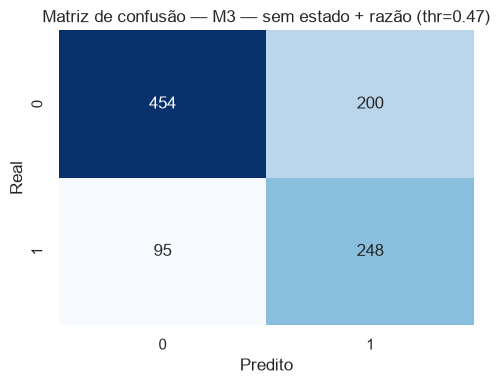

In [13]:
melhor_modelo_nome = cv_resultados.iloc[0]["modelo"]
melhor_modelo = modelos_teste[melhor_modelo_nome]
melhores_features = feature_sets[melhor_modelo_nome]

# Usa threshold otimizado no CV
threshold_final = best_threshold_champion
melhor_pred = (melhor_modelo.predict_proba(X_test[melhores_features])[:, 1] >= threshold_final).astype(int)
melhor_prob = melhor_modelo.predict_proba(X_test[melhores_features])[:, 1]

print(f"Modelo selecionado pela PR-AUC média da validação cruzada: {melhor_modelo_nome}")
print(f"Variáveis utilizadas: {', '.join(melhores_features)}")
print(f"Threshold aplicado (otimizado no CV): {threshold_final:.3f}")
print()
print("Relatório de classificação no teste:")
print(classification_report(y_test, melhor_pred, target_names=["Adimplente", "Inadimplente"], zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, melhor_pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(title=f"Matriz de confusão — {melhor_modelo_nome} (thr={threshold_final:.2f})", xlabel="Predito", ylabel="Real")
plt.tight_layout()
plt.show()

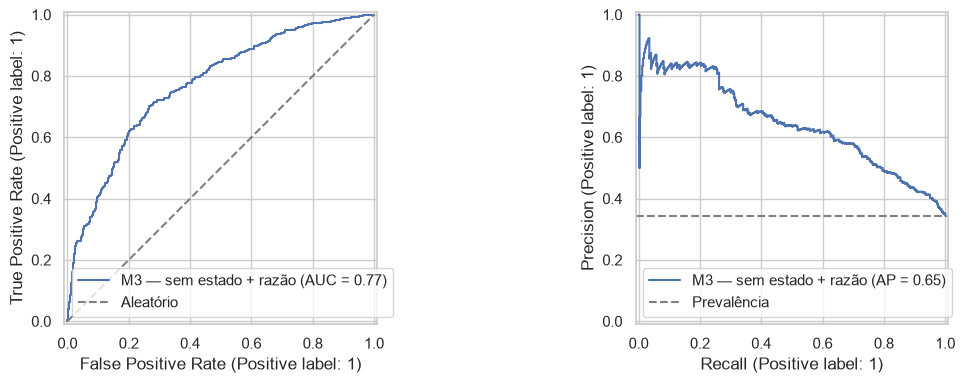

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, melhor_prob, ax=axes[0], name=melhor_modelo_nome)
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
axes[0].legend()
PrecisionRecallDisplay.from_predictions(y_test, melhor_prob, ax=axes[1], name=melhor_modelo_nome)
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Prevalência")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Interpretação da Regressão Logística

Para variáveis **numéricas**, os coeficientes correspondem ao efeito de aproximadamente **um desvio-padrão**, pois houve padronização (StandardScaler) no pipeline. 

Para variáveis **categóricas** (one-hot encoded), cada coeficiente é relativo à **categoria de referência** (a primeira categoria alfabética omitida pelo encoder).

`odds_ratio > 1` indica associação com aumento das chances estimadas de inadimplência; `odds_ratio < 1` indica redução. **Associação não implica causalidade.**

In [15]:
pre_processamento = melhor_modelo.named_steps["pre_processamento"]
classificador = melhor_modelo.named_steps["modelo"]
nomes_atributos = pre_processamento.get_feature_names_out()
coeficientes = classificador.coef_[0]
coeficientes_df = pd.DataFrame({
    "atributo": nomes_atributos,
    "coeficiente": coeficientes,
    "odds_ratio": np.exp(coeficientes),
})

# Separa numéricas (padronizadas: OR por 1 DP) e categóricas (vs referência)
numericas_mask = coeficientes_df["atributo"].str.startswith("numericas__")
categoricas_mask = coeficientes_df["atributo"].str.startswith("categoricas__")

num_df = coeficientes_df[numericas_mask].copy()
cat_df = coeficientes_df[categoricas_mask].copy()

# Limpa nomes para exibição
num_df["feature"] = num_df["atributo"].str.replace("numericas__", "")
cat_df["feature"] = cat_df["atributo"].str.replace("categoricas__", "").str.replace("_", " ")

print("=== VARIÁVEIS NUMÉRICAS — Odds Ratio por 1 Desvio-Padrão ===")
print("(OR > 1: aumenta risco | OR < 1: reduz risco)")
display(num_df[["feature", "coeficiente", "odds_ratio"]].sort_values("coeficiente", ascending=False).round(3))

print("\n=== VARIÁVEIS CATEGÓRICAS — Odds Ratio vs Categoria de Referência ===")
print("(Referência: primeira categoria alfabética omitida pelo OneHotEncoder)")
display(cat_df[["feature", "coeficiente", "odds_ratio"]].sort_values("coeficiente", ascending=False).round(3))

# Top associações gerais (para resumo)
print("\n=== TOP 10 MAIORES ASSOCIAÇÕES POSITIVAS (risco ↑) ===")
top_pos = coeficientes_df.nlargest(10, "coeficiente")
display(top_pos[["atributo", "coeficiente", "odds_ratio"]].round(3))

print("=== TOP 10 MAIORES ASSOCIAÇÕES NEGATIVAS (risco ↓) ===")
top_neg = coeficientes_df.nsmallest(10, "coeficiente")
display(top_neg[["atributo", "coeficiente", "odds_ratio"]].round(3))

=== VARIÁVEIS NUMÉRICAS — Odds Ratio por 1 Desvio-Padrão ===
(OR > 1: aumenta risco | OR < 1: reduz risco)


,feature,coeficiente,odds_ratio
7,razao_emprestimo_renda,0.630,1.878
6,dividas_ativas,0.456,1.578
4,valor_solicitado,0.131,1.140
0,idade,-0.110,0.896
5,prazo_meses,-0.230,0.795
2,tempo_emprego_anos,-0.260,0.771
1,renda_mensal,-0.336,0.715
3,score_credito,-0.801,0.449



=== VARIÁVEIS CATEGÓRICAS — Odds Ratio vs Categoria de Referência ===
(Referência: primeira categoria alfabética omitida pelo OneHotEncoder)


,feature,coeficiente,odds_ratio
15,finalidade Saude,0.127,1.136
9,escolaridade Ensino Medio,0.077,1.080
11,escolaridade Pos Graduacao,0.041,1.042
13,finalidade Outros,-0.026,0.975
17,finalidade Viagem,-0.045,0.956
12,finalidade Educacao,-0.049,0.952
16,finalidade Veiculo,-0.054,0.947
14,finalidade Reforma,-0.077,0.926
10,escolaridade Ensino Superior,-0.098,0.907
8,escolaridade Ensino Fundamental,-0.143,0.867



=== TOP 10 MAIORES ASSOCIAÇÕES POSITIVAS (risco ↑) ===


,atributo,coeficiente,odds_ratio
7,numericas__razao_emprestimo_renda,0.630,1.878
6,numericas__dividas_ativas,0.456,1.578
4,numericas__valor_solicitado,0.131,1.140
15,categoricas__finalidade_Saude,0.127,1.136
9,categoricas__escolaridade_Ensino Medio,0.077,1.080
11,categoricas__escolaridade_Pos Graduacao,0.041,1.042
13,categoricas__finalidade_Outros,-0.026,0.975
17,categoricas__finalidade_Viagem,-0.045,0.956
12,categoricas__finalidade_Educacao,-0.049,0.952
16,categoricas__finalidade_Veiculo,-0.054,0.947


=== TOP 10 MAIORES ASSOCIAÇÕES NEGATIVAS (risco ↓) ===


,atributo,coeficiente,odds_ratio
3,numericas__score_credito,-0.801,0.449
1,numericas__renda_mensal,-0.336,0.715
2,numericas__tempo_emprego_anos,-0.260,0.771
5,numericas__prazo_meses,-0.230,0.795
8,categoricas__escolaridade_Ensino Fundamental,-0.143,0.867
0,numericas__idade,-0.110,0.896
10,categoricas__escolaridade_Ensino Superior,-0.098,0.907
14,categoricas__finalidade_Reforma,-0.077,0.926
16,categoricas__finalidade_Veiculo,-0.054,0.947
12,categoricas__finalidade_Educacao,-0.049,0.952


## 8. Conclusão, limitações e cuidados

### Conclusão

A análise compara um baseline simples com versões da Regressão Logística e verifica o ganho da variável derivada de comprometimento da renda. A escolha final deve considerar especialmente PR-AUC e recall da classe inadimplente, pois perder um caso de risco pode ser mais relevante do que maximizar a acurácia geral.

### Limitações

- Os dados são sintéticos e não comprovam desempenho em uma carteira real.
- Não há dimensão temporal para validar estabilidade e drift.
- O limiar padrão de 0,5 não representa necessariamente o custo real de falso positivo e falso negativo.
- `estado` pode funcionar como proxy geográfico; por isso foi comparado com uma versão sem essa variável.
- O modelo identifica associação preditiva, não causalidade.

Em produção seriam necessários validação temporal, análise de fairness, definição de custos de decisão, monitoramento de drift, governança e revisão humana.

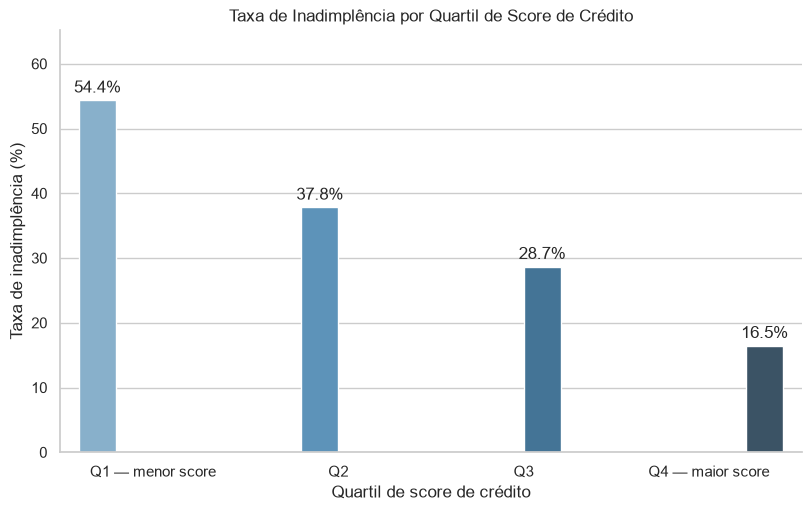

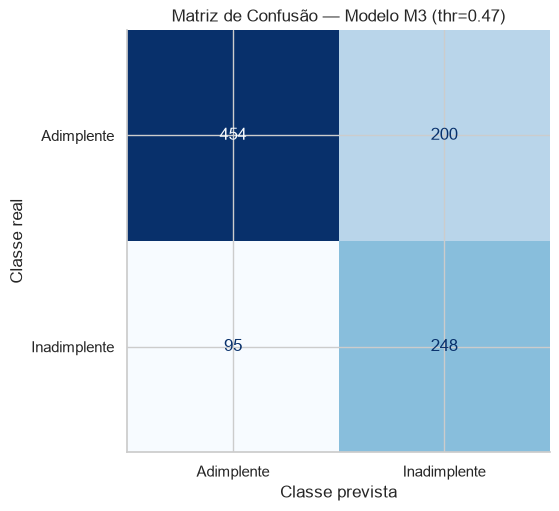

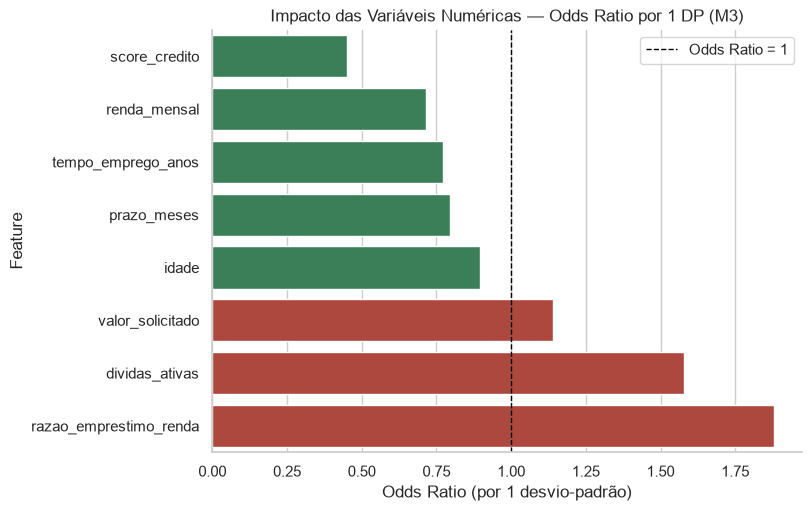

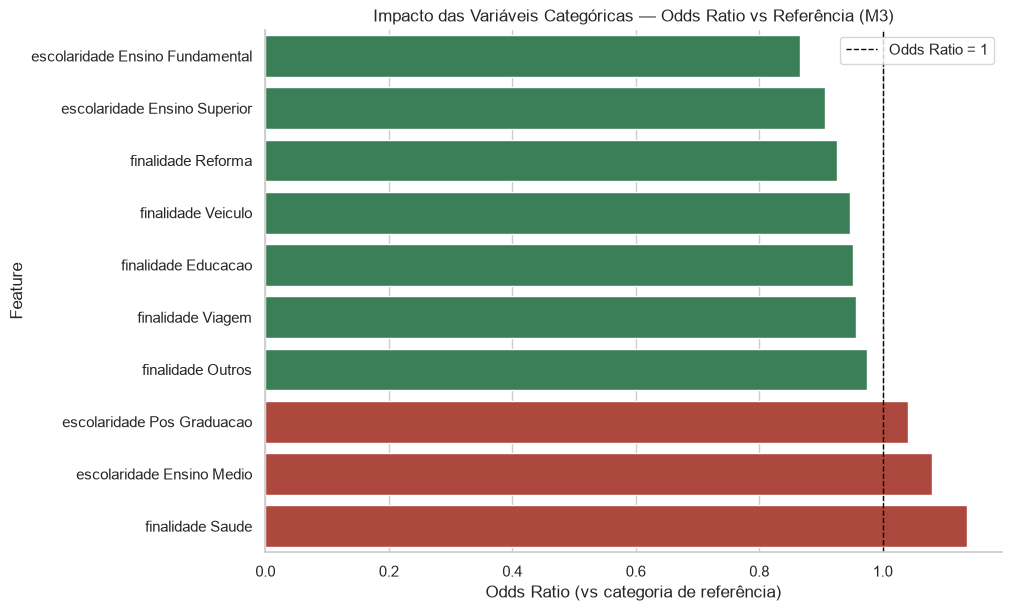

Imagens salvas em: D:\lab\Analise_Credito\desafios\analise-credito\imagens


In [16]:
import os

IMAGENS_DIR = PROJECT_DIR / "imagens"
os.makedirs(IMAGENS_DIR, exist_ok=True)

# Gráfico 1 — taxa de inadimplência por quartil de score.
score_quartis = df[["score_credito", "inadimplente"]].copy()
score_quartis["quartil_score"] = pd.qcut(
    score_quartis["score_credito"],
    q=4,
    labels=["Q1 — menor score", "Q2", "Q3", "Q4 — maior score"],
)
taxa_score = (
    score_quartis.groupby("quartil_score", observed=True)["inadimplente"]
    .mean()
    .mul(100)
    .reset_index(name="taxa_inadimplencia")
)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
sns.barplot(
    data=taxa_score,
    x="quartil_score",
    y="taxa_inadimplencia",
    hue="quartil_score",
    palette="Blues_d",
    legend=False,
    ax=ax,
)
ax.set_title("Taxa de Inadimplência por Quartil de Score de Crédito")
ax.set_xlabel("Quartil de score de crédito")
ax.set_ylabel("Taxa de inadimplência (%)")
ax.set_ylim(0, max(taxa_score["taxa_inadimplencia"]) * 1.2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGENS_DIR / "taxa_inadimplencia_score.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Gráfico 2 — matriz de confusão do M3 no conjunto de teste.
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    melhor_pred,
    display_labels=["Adimplente", "Inadimplente"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=ax,
)
ax.set_title(f"Matriz de Confusão — Modelo M3 (thr={threshold_final:.2f})")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGENS_DIR / "matriz_confusao_m3.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Gráfico 3 — odds ratios NUMÉRICAS do M3 (por 1 DP).
num_plot = num_df.copy()
num_plot = num_plot.sort_values("odds_ratio", ascending=True)
num_plot["cor"] = np.where(num_plot["odds_ratio"] > 1, "red", "green")
paleta_odds = {"red": "#C0392B", "green": "#2E8B57"}

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
sns.barplot(
    data=num_plot,
    x="odds_ratio",
    y="feature",
    hue="cor",
    palette=paleta_odds,
    dodge=False,
    legend=False,
    ax=ax,
)
ax.axvline(1, color="black", linewidth=1, linestyle="--", label="Odds Ratio = 1")
ax.set_title("Impacto das Variáveis Numéricas — Odds Ratio por 1 DP (M3)")
ax.set_xlabel("Odds Ratio (por 1 desvio-padrão)")
ax.set_ylabel("Feature")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGENS_DIR / "odds_ratio_numericas.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Gráfico 4 — odds ratios CATEGÓRICAS do M3 (vs referência).
cat_plot = cat_df.copy()
cat_plot = cat_plot.sort_values("odds_ratio", ascending=True)
cat_plot["cor"] = np.where(cat_plot["odds_ratio"] > 1, "red", "green")

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
sns.barplot(
    data=cat_plot,
    x="odds_ratio",
    y="feature",
    hue="cor",
    palette=paleta_odds,
    dodge=False,
    legend=False,
    ax=ax,
)
ax.axvline(1, color="black", linewidth=1, linestyle="--", label="Odds Ratio = 1")
ax.set_title("Impacto das Variáveis Categóricas — Odds Ratio vs Referência (M3)")
ax.set_xlabel("Odds Ratio (vs categoria de referência)")
ax.set_ylabel("Feature")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGENS_DIR / "odds_ratio_categoricas.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Imagens salvas em: {IMAGENS_DIR.resolve()}")

### Bônus: Modelo Challenger (Maximizando Performance)

O modelo Challenger usa LightGBM, que lida melhor com não-linearidades e interações entre atributos do que a Regressão Logística. 

Para comparação justa com o Champion, o Challenger usa o **mesmo pré-processamento** (imputação pela mediana, one-hot encoding) — apenas o algoritmo difere.

O limiar de decisão é otimizado via **validação cruzada no treino** (não no teste) para maximizar F1-score, evitando *test leakage*.

In [17]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_predict

# O Challenger usa as mesmas features do Champion para comparar os algoritmos
# sob a mesma informação disponível.
features_challenger = melhores_features
numeric_features_challenger = [
    feature
    for feature in features_challenger
    if feature not in ["estado", "escolaridade", "finalidade"]
]
categorical_features_challenger = [
    feature
    for feature in features_challenger
    if feature in ["estado", "escolaridade", "finalidade"]
]

# Pré-processamento IDÊNTICO ao Champion (SimpleImputer + OneHotEncoder).
# LightGBM não precisa de StandardScaler.
preprocessor_challenger = ColumnTransformer(
    transformers=[
        ("numericas", SimpleImputer(strategy="median"), numeric_features_challenger),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features_challenger,
        ),
    ],
    remainder="drop",
)

# LightGBM com class_weight='balanced' para lidar com desbalanceamento.
challenger_pipeline = Pipeline(
    steps=[
        ("pre_processamento", preprocessor_challenger),
        (
            "modelo",
            LGBMClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_estimators=300,
                learning_rate=0.05,
                num_leaves=31,
                n_jobs=1,
                verbosity=-1,
            ),
        ),
    ]
)

# Treina no treino completo
challenger_pipeline.fit(X_train[features_challenger], y_train)

# --- Seleção de threshold via VALIDAÇÃO CRUZADA no treino (sem test leakage) ---
# Usa cross_val_predict para obter probabilidades out-of-fold no treino
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_prob_cv = cross_val_predict(
    challenger_pipeline,
    X_train[features_challenger],
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1,
)[:, 1]

# Busca threshold que maximiza F1 no CV
thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = [f1_score(y_train, (y_prob_cv >= t).astype(int), zero_division=0) for t in thresholds]
best_threshold = thresholds[np.argmax(f1_scores)]
best_f1 = max(f1_scores)

print(f"Threshold ótimo (CV F1-max): {best_threshold:.3f} | F1 médio CV: {best_f1:.3f}")

# Aplica threshold selecionado no TESTE
y_prob_challenger = challenger_pipeline.predict_proba(
    X_test[features_challenger]
)[:, 1]

y_pred_challenger = (y_prob_challenger >= best_threshold).astype(int)

metricas_challenger = {
    "PR-AUC": average_precision_score(y_test, y_prob_challenger),
    "ROC-AUC": roc_auc_score(y_test, y_prob_challenger),
    "Recall": recall_score(y_test, y_pred_challenger, zero_division=0),
    "Precisão": precision_score(y_test, y_pred_challenger, zero_division=0),
    "F1": f1_score(y_test, y_pred_challenger, zero_division=0),
}

print(f"Threshold aplicado no teste: {best_threshold:.3f}")
for nome_metrica, valor in metricas_challenger.items():
    print(f"{nome_metrica}: {valor:.3f}")

Threshold ótimo (CV F1-max): 0.340 | F1 médio CV: 0.605
Threshold aplicado no teste: 0.340
PR-AUC: 0.638
ROC-AUC: 0.765
Recall: 0.758
Precisão: 0.513
F1: 0.612


## Aplicação Prática: Política de Crédito e Escoragem

Após a seleção e validação do M3, o pipeline é ajustado na base tratada completa
para gerar uma escoragem operacional para todas as propostas.

In [18]:
# O dataset_tratado.csv permanece dedicado ao pré-processamento e treino/teste.
# O resultado comercial é gravado separadamente em resultado_politica_credito.csv.
pipeline_m3_politica = criar_pipeline(melhores_features, class_weight="balanced")
pipeline_m3_politica.fit(df[melhores_features], df[alvo])

# Pontuação da base tratada completa após o ajuste final do M3.
probabilidades = pipeline_m3_politica.predict_proba(df[melhores_features])[:, 1]
resultado_politica_credito = df.copy()
resultado_politica_credito["probabilidade_inadimplencia"] = pd.Series(
    probabilidades, index=resultado_politica_credito.index
).round(4)

resultado_politica_credito["status_credito"] = np.select(
    [
        resultado_politica_credito["probabilidade_inadimplencia"] < 0.30,
        resultado_politica_credito["probabilidade_inadimplencia"].between(0.30, 0.60, inclusive="both"),
    ],
    ["Disponivel", "Analise Manual"],
    default="Indisponivel",
)

# Cada dívida ativa reduz proporcionalmente o limite base: fator 1 / (1 + dívidas).
fator_dividas = 1 / (1 + resultado_politica_credito["dividas_ativas"])
limite_base = (
    resultado_politica_credito["renda_mensal"]
    * 2.5
    * (1 - resultado_politica_credito["probabilidade_inadimplencia"])
    * fator_dividas
)
limite_seguro = limite_base.clip(
    upper=resultado_politica_credito["valor_solicitado"]
)
resultado_politica_credito["valor_pre_aprovado"] = np.where(
    resultado_politica_credito["status_credito"].eq("Disponivel"),
    limite_seguro,
    0.0,
)
resultado_politica_credito["valor_pre_aprovado"] = resultado_politica_credito[
    "valor_pre_aprovado"
].round(2)

ordem_status = ["Disponivel", "Analise Manual", "Indisponivel"]
resumo_politica = (
    resultado_politica_credito.groupby("status_credito", observed=False)
    .agg(
        quantidade=("status_credito", "size"),
        percentual=("status_credito", lambda serie: serie.size / len(resultado_politica_credito) * 100),
        ticket_medio_pre_aprovado=("valor_pre_aprovado", "mean"),
        volume_financeiro=("valor_pre_aprovado", "sum"),
    )
    .reindex(ordem_status, fill_value=0)
)

disponiveis = resultado_politica_credito["status_credito"].eq("Disponivel")
ticket_medio_disponivel = resultado_politica_credito.loc[
    disponiveis, "valor_pre_aprovado"
].mean()
volume_liberado_seguro = resultado_politica_credito.loc[
    disponiveis, "valor_pre_aprovado"
].sum()
percentual_aprovacao_automatica = disponiveis.mean() * 100

print("=== RESUMO EXECUTIVO — POLÍTICA DE CRÉDITO ===")
display(resumo_politica.round({"percentual": 2, "ticket_medio_pre_aprovado": 2, "volume_financeiro": 2}))
print(f"Percentual de aprovação automática: {percentual_aprovacao_automatica:.2f}%")
print(f"Ticket médio pré-aprovado: R$ {ticket_medio_disponivel:,.2f}")
print(f"Volume financeiro liberado com segurança: R$ {volume_liberado_seguro:,.2f}")

resultado_politica_credito.to_csv(
    PROJECT_DIR / "resultado_politica_credito.csv",
    index=False,
    encoding="utf-8",
)
print("Arquivo gerado: resultado_politica_credito.csv")

=== RESUMO EXECUTIVO — POLÍTICA DE CRÉDITO ===


,quantidade,percentual,ticket_medio_pre_aprovado,volume_financeiro
status_credito,,,,
Disponivel,1461,29.330,"6,809.830","9,949,155.740"
Analise Manual,1986,39.870,0.000,0.000
Indisponivel,1534,30.800,0.000,0.000


Percentual de aprovação automática: 29.33%
Ticket médio pré-aprovado: R$ 6,809.83
Volume financeiro liberado com segurança: R$ 9,949,155.74
Arquivo gerado: resultado_politica_credito.csv


In [19]:
import json

cliente_disponivel = resultado_politica_credito.loc[
    resultado_politica_credito["status_credito"].eq("Disponivel")
].iloc[0]

valor_pre_aprovado_brl = (
    f"R$ {cliente_disponivel['valor_pre_aprovado']:,.2f}"
    .replace(",", "X")
    .replace(".", ",")
    .replace("X", ".")
)
finalidade_cliente = cliente_disponivel["finalidade"]
mensagem_whatsapp = (
    f"🎉 CredAIR: você tem R$ {valor_pre_aprovado_brl.removeprefix('R$ ')} "
    f"pré-aprovados para realizar seu plano de {finalidade_cliente}. "
    "É rápido, seguro e sem burocracia. Acesse agora e continue sua contratação!"
)

payload_crm = {
    "canal": "whatsapp",
    "status_credito": cliente_disponivel["status_credito"],
    "valor_pre_aprovado": valor_pre_aprovado_brl,
    "finalidade": finalidade_cliente,
    "mensagem": mensagem_whatsapp,
}

print("=== Preview de Disparo Automatizado (CRM) ===")
print(json.dumps(payload_crm, ensure_ascii=False, indent=2))

=== Preview de Disparo Automatizado (CRM) ===
{
  "canal": "whatsapp",
  "status_credito": "Disponivel",
  "valor_pre_aprovado": "R$ 3.021,01",
  "finalidade": "Viagem",
  "mensagem": "🎉 CredAIR: você tem R$ 3.021,01 pré-aprovados para realizar seu plano de Viagem. É rápido, seguro e sem burocracia. Acesse agora e continue sua contratação!"
}
